In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData'

# List all distance folders
folders = os.listdir(dataset_path)
print("Distance folders found:")
print(sorted(folders))

Distance folders found:
['14ft', '20ft', '26ft', '2ft', '32ft', '38ft', '44ft', '50ft', '56ft', '62ft', '8ft']


In [ ]:
# Look inside 2ft folder
two_ft_path = os.path.join(dataset_path, '2ft')
files = os.listdir(two_ft_path)

print(f"Number of files in 2ft: {len(files)}")
print("\nFirst 10 files:")
for f in sorted(files)[:10]:
    print(f)

Number of files in 2ft: 64

First 10 files:
WiFi_air_X310_3123D52_2ft_run1.sigmf-data
WiFi_air_X310_3123D52_2ft_run1.sigmf-meta
WiFi_air_X310_3123D52_2ft_run2.sigmf-data
WiFi_air_X310_3123D52_2ft_run2.sigmf-meta
WiFi_air_X310_3123D54_2ft_run1.sigmf-data
WiFi_air_X310_3123D54_2ft_run1.sigmf-meta
WiFi_air_X310_3123D54_2ft_run2.sigmf-data
WiFi_air_X310_3123D54_2ft_run2.sigmf-meta
WiFi_air_X310_3123D58_2ft_run1.sigmf-data
WiFi_air_X310_3123D58_2ft_run1.sigmf-meta


In [ ]:
import numpy as np

# Pick one file to open
file_path = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData/2ft/WiFi_air_X310_3123D7B_2ft_run1.sigmf-data'

# IMPORTANT: must use complex128 not complex64
raw_iq = np.fromfile(file_path, dtype=np.complex128)

print(f"Type of data: {type(raw_iq)}")
print(f"Shape: {raw_iq.shape}")
print(f"Total samples: {len(raw_iq)}")
print(f"\nFirst 5 samples:")
print(raw_iq[:5])
print(f"\nReal part (I channel) first 5: {raw_iq[:5].real}")
print(f"Imaginary part (Q channel) first 5: {raw_iq[:5].imag}")

Type of data: <class 'numpy.ndarray'>
Shape: (20006400,)
Total samples: 20006400

First 5 samples:
[-0.00726341-0.00994903j -0.01113926-0.01617481j -0.00698874-0.02203436j
 -0.00332652-0.00824j     0.00308237-0.02182074j]

Real part (I channel) first 5: [-0.00726341 -0.01113926 -0.00698874 -0.00332652  0.00308237]
Imaginary part (Q channel) first 5: [-0.00994903 -0.01617481 -0.02203436 -0.00824    -0.02182074]


In [ ]:
import os
import re

dataset_path = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData'

device_ids = set()

# Walk through all distance folders
for dist_folder in os.listdir(dataset_path):
    dist_path = os.path.join(dataset_path, dist_folder)
    if os.path.isdir(dist_path):
        for filename in os.listdir(dist_path):
            if filename.endswith('.sigmf-data'):
                # Extract device ID from filename
                # Format: WiFi_air_X310_DEVICEID_XXft_runN.sigmf-data
                parts = filename.split('_')
                device_id = parts[3]  # 4th part is the device ID
                device_ids.add(device_id)

device_ids = sorted(list(device_ids))
print(f"Total unique devices found: {len(device_ids)}")
print("\nDevice IDs:")
for i, d in enumerate(device_ids):
    print(f"  Class {i}: {d}")

# Create a mapping: device_id → class number
device_to_label = {dev: idx for idx, dev in enumerate(device_ids)}
print("\nDevice to Label mapping:")
print(device_to_label)

Total unique devices found: 16

Device IDs:
  Class 0: 3123D52
  Class 1: 3123D54
  Class 2: 3123D58
  Class 3: 3123D64
  Class 4: 3123D65
  Class 5: 3123D70
  Class 6: 3123D76
  Class 7: 3123D78
  Class 8: 3123D79
  Class 9: 3123D7B
  Class 10: 3123D7D
  Class 11: 3123D7E
  Class 12: 3123D80
  Class 13: 3123D89
  Class 14: 3123EFE
  Class 15: 3124E4A

Device to Label mapping:
{'3123D52': 0, '3123D54': 1, '3123D58': 2, '3123D64': 3, '3123D65': 4, '3123D70': 5, '3123D76': 6, '3123D78': 7, '3123D79': 8, '3123D7B': 9, '3123D7D': 10, '3123D7E': 11, '3123D80': 12, '3123D89': 13, '3123EFE': 14, '3124E4A': 15}


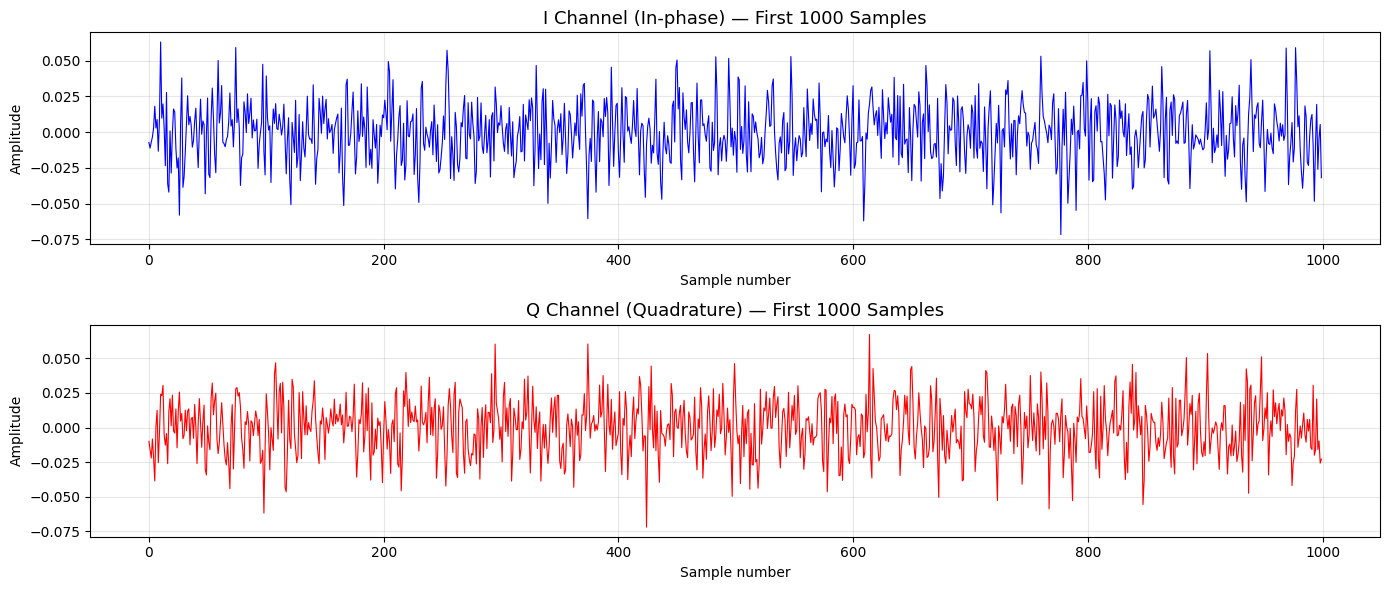

Plot saved!


In [ ]:
import matplotlib.pyplot as plt

# Load one file
file_path = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData/2ft/WiFi_air_X310_3123D7B_2ft_run1.sigmf-data'
raw_iq = np.fromfile(file_path, dtype=np.complex128)

# Take first 1000 samples only (for plotting)
samples = raw_iq[:1000]

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# Plot I channel
axes[0].plot(samples.real, color='blue', linewidth=0.8)
axes[0].set_title('I Channel (In-phase) — First 1000 Samples', fontsize=13)
axes[0].set_xlabel('Sample number')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True, alpha=0.3)

# Plot Q channel
axes[1].plot(samples.imag, color='red', linewidth=0.8)
axes[1].set_title('Q Channel (Quadrature) — First 1000 Samples', fontsize=13)
axes[1].set_xlabel('Sample number')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('iq_signal.png', dpi=150)
plt.show()
print("Plot saved!")

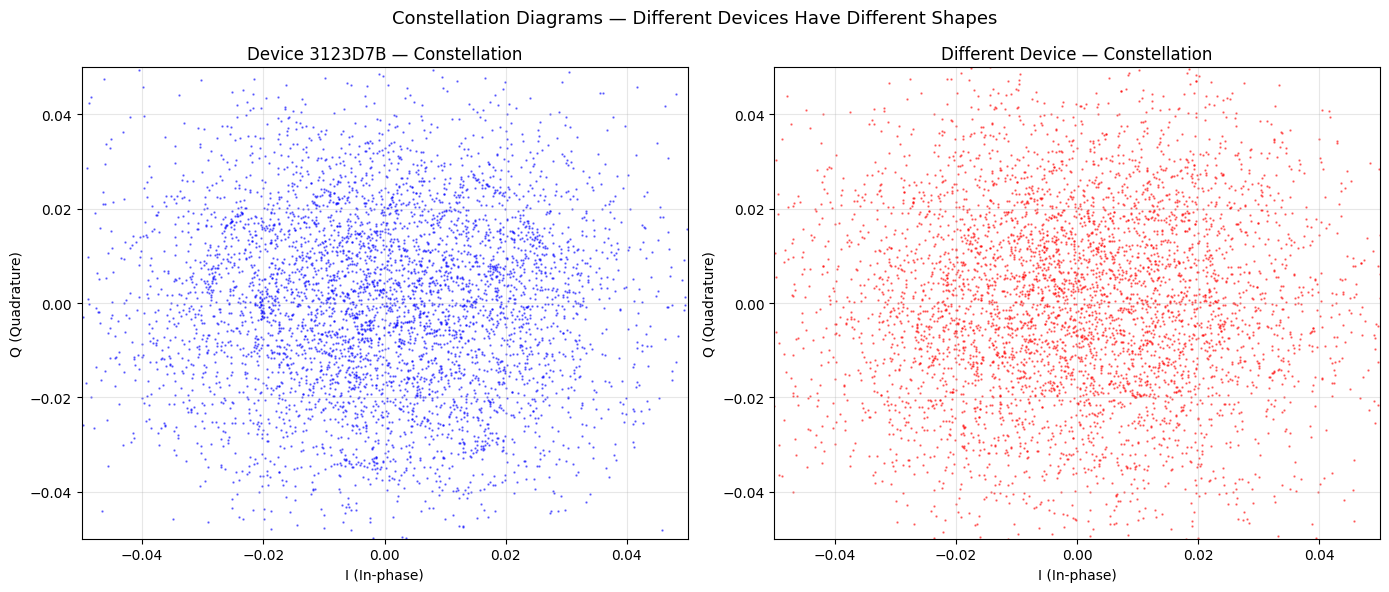

In [ ]:
# Constellation diagram shows I vs Q as a scatter plot
# Hardware imperfections show up as distortions in this pattern

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Load two different devices
file1 = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData/2ft/WiFi_air_X310_3123D7B_2ft_run1.sigmf-data'

# Find a second device file
second_device = None
for f in os.listdir('/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData/2ft/'):
    if '3123D7B' not in f and f.endswith('.sigmf-data'):
        second_device = f
        break

file2 = f'/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData/2ft/{second_device}'

iq1 = np.fromfile(file1, dtype=np.complex128)[:5000]
iq2 = np.fromfile(file2, dtype=np.complex128)[:5000]

axes[0].scatter(iq1.real, iq1.imag, s=0.5, alpha=0.5, color='blue')
axes[0].set_title(f'Device 3123D7B — Constellation', fontsize=12)
axes[0].set_xlabel('I (In-phase)')
axes[0].set_ylabel('Q (Quadrature)')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(-0.05, 0.05)
axes[0].set_ylim(-0.05, 0.05)

axes[1].scatter(iq2.real, iq2.imag, s=0.5, alpha=0.5, color='red')
axes[1].set_title(f'Different Device — Constellation', fontsize=12)
axes[1].set_xlabel('I (In-phase)')
axes[1].set_ylabel('Q (Quadrature)')
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(-0.05, 0.05)
axes[1].set_ylim(-0.05, 0.05)

plt.suptitle('Constellation Diagrams — Different Devices Have Different Shapes', fontsize=13)
plt.tight_layout()
plt.savefig('constellation.png', dpi=150)
plt.show()

Spectrogram shape: (256, 780)
Frequency bins: 256
Time steps: 780


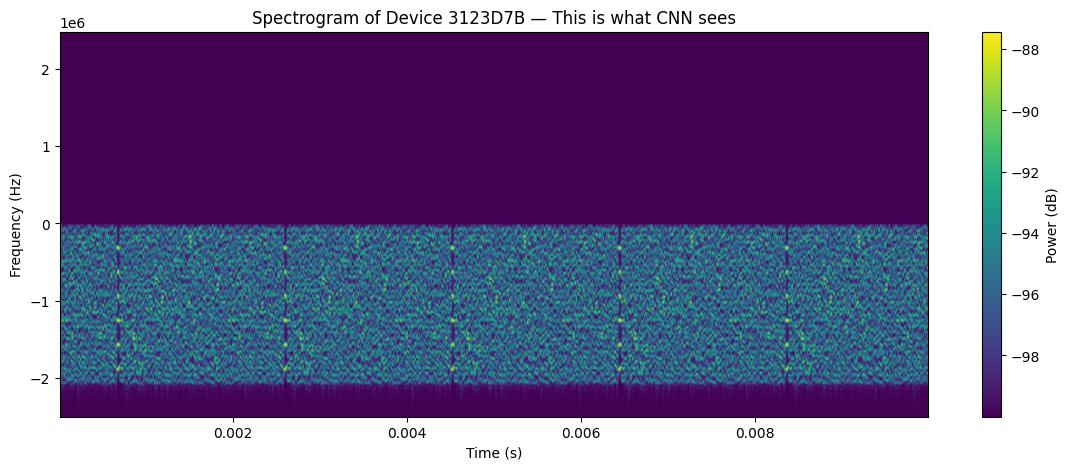

Spectrogram shape ready for CNN: (256, 780)


In [ ]:
from scipy import signal as scipy_signal

# Load raw IQ
file_path = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData/2ft/WiFi_air_X310_3123D7B_2ft_run1.sigmf-data'
raw_iq = np.fromfile(file_path, dtype=np.complex128)

# Take a chunk (first 50000 samples)
chunk = raw_iq[:50000]

# Apply STFT
sampling_rate = 5e6  # 5 MHz

frequencies, times, Sxx = scipy_signal.spectrogram(
    chunk,
    fs=sampling_rate,
    nperseg=128,        # window size
    noverlap=64,        # 50% overlap
    nfft=256,           # FFT points
    return_onesided=False  # complex signal needs two-sided
)

# Convert to dB
Sxx_db = 10 * np.log10(np.abs(Sxx) + 1e-10)

print(f"Spectrogram shape: {Sxx_db.shape}")
print(f"Frequency bins: {Sxx_db.shape[0]}")
print(f"Time steps: {Sxx_db.shape[1]}")

# Plot it
plt.figure(figsize=(14, 5))
plt.pcolormesh(times, frequencies, Sxx_db,
               shading='gouraud', cmap='viridis')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.title('Spectrogram of Device 3123D7B — This is what CNN sees')
plt.colorbar(label='Power (dB)')
plt.savefig('spectrogram.png', dpi=150)
plt.show()
print(f"Spectrogram shape ready for CNN: {Sxx_db.shape}")

In [ ]:
import numpy as np
import os
import re
from scipy import signal as scipy_signal
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

print(f"PyTorch version: {torch.__version__}")
print(f"GPU available: {torch.cuda.is_available()}")

# Use GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.10.0+cu128
GPU available: True
Using device: cuda


In [ ]:
def load_iq_file(filepath, samples_per_chunk=128*32, num_chunks=50):
    """
    Load one .sigmf-data file and return spectrogram chunks.

    Each chunk = one training sample (one 2D image for CNN)
    """
    # Load raw IQ
    raw_iq = np.fromfile(filepath, dtype=np.complex128)

    chunks = []

    for i in range(num_chunks):
        # Take a chunk of IQ samples
        start = i * samples_per_chunk
        end   = start + samples_per_chunk

        if end > len(raw_iq):
            break

        chunk_iq = raw_iq[start:end]

        # Apply STFT to get spectrogram
        _, _, Sxx = scipy_signal.spectrogram(
            chunk_iq,
            fs=5e6,
            nperseg=128,
            noverlap=64,
            nfft=256,
            return_onesided=False
        )

        # Convert to dB
        Sxx_db = 10 * np.log10(np.abs(Sxx) + 1e-10)

        # Normalize to 0-1 range
        Sxx_min = Sxx_db.min()
        Sxx_max = Sxx_db.max()
        if Sxx_max - Sxx_min > 0:
            Sxx_norm = (Sxx_db - Sxx_min) / (Sxx_max - Sxx_min)
        else:
            Sxx_norm = Sxx_db

        chunks.append(Sxx_norm.astype(np.float32))

    return chunks  # list of (256, 32) arrays

In [ ]:
def load_dataset(dataset_path, distance='2ft', num_chunks_per_file=30):
    """
    Load all device files from one distance folder.
    Returns X (spectrograms) and y (labels).
    """
    dist_path = os.path.join(dataset_path, distance)

    # Get all device IDs first
    device_ids = set()
    for f in os.listdir(dist_path):
        if f.endswith('.sigmf-data'):
            device_id = f.split('_')[3]
            device_ids.add(device_id)

    device_ids    = sorted(list(device_ids))
    device_to_lbl = {d: i for i, d in enumerate(device_ids)}

    print(f"Found {len(device_ids)} devices")
    print(f"Loading from: {distance} folder")

    X, y = [], []

    for filename in sorted(os.listdir(dist_path)):
        if not filename.endswith('.sigmf-data'):
            continue

        device_id = filename.split('_')[3]
        label     = device_to_lbl[device_id]
        filepath  = os.path.join(dist_path, filename)

        print(f"  Loading {filename[:40]}... label={label}")

        chunks = load_iq_file(filepath,
                              num_chunks=num_chunks_per_file)

        X.extend(chunks)
        y.extend([label] * len(chunks))

    X = np.array(X)   # shape: (N, 256, 32)
    y = np.array(y)   # shape: (N,)

    print(f"\nDataset loaded!")
    print(f"X shape: {X.shape}  →  (samples, freq_bins, time_steps)")
    print(f"y shape: {y.shape}")
    print(f"Classes: {np.unique(y)}")

    return X, y, device_ids

# Load dataset — start with 2ft for speed
dataset_path = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData'

X, y, device_ids = load_dataset(dataset_path,
                                 distance='2ft',
                                 num_chunks_per_file=30)

Found 16 devices
Loading from: 2ft folder
  Loading WiFi_air_X310_3123D52_2ft_run1.sigmf-dat... label=0
  Loading WiFi_air_X310_3123D52_2ft_run2.sigmf-dat... label=0
  Loading WiFi_air_X310_3123D54_2ft_run1.sigmf-dat... label=1
  Loading WiFi_air_X310_3123D54_2ft_run2.sigmf-dat... label=1
  Loading WiFi_air_X310_3123D58_2ft_run1.sigmf-dat... label=2
  Loading WiFi_air_X310_3123D58_2ft_run2.sigmf-dat... label=2
  Loading WiFi_air_X310_3123D64_2ft_run1.sigmf-dat... label=3
  Loading WiFi_air_X310_3123D64_2ft_run2.sigmf-dat... label=3
  Loading WiFi_air_X310_3123D65_2ft_run1.sigmf-dat... label=4
  Loading WiFi_air_X310_3123D65_2ft_run2.sigmf-dat... label=4
  Loading WiFi_air_X310_3123D70_2ft_run1.sigmf-dat... label=5
  Loading WiFi_air_X310_3123D70_2ft_run2.sigmf-dat... label=5
  Loading WiFi_air_X310_3123D76_2ft_run1.sigmf-dat... label=6
  Loading WiFi_air_X310_3123D76_2ft_run2.sigmf-dat... label=6
  Loading WiFi_air_X310_3123D78_2ft_run1.sigmf-dat... label=7
  Loading WiFi_air_X310_3123

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # equal samples per class in both splits
)

print(f"Training samples:  {X_train.shape[0]}")
print(f"Testing samples:   {X_test.shape[0]}")
print(f"Spectrogram shape: {X_train.shape[1:]}")

# Add channel dimension for CNN (N, 1, 256, 32)
X_train_cnn = X_train[:, np.newaxis, :, :]
X_test_cnn  = X_test[:,  np.newaxis, :, :]

print(f"\nCNN input shape: {X_train_cnn.shape}")
print(f"  (samples, channels, freq_bins, time_steps)")

Training samples:  768
Testing samples:   192
Spectrogram shape: (256, 63)

CNN input shape: (768, 1, 256, 63)
  (samples, channels, freq_bins, time_steps)


In [ ]:
class RFDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create datasets
train_dataset = RFDataset(X_train_cnn, y_train)
test_dataset  = RFDataset(X_test_cnn,  y_test)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=32,
                          shuffle=False)

print(f"Training batches:  {len(train_loader)}")
print(f"Testing batches:   {len(test_loader)}")

# Check one batch
for xb, yb in train_loader:
    print(f"\nOne batch — X shape: {xb.shape}")
    print(f"One batch — y shape: {yb.shape}")
    print(f"Labels in batch: {yb[:10]}")
    break

Training batches:  24
Testing batches:   6

One batch — X shape: torch.Size([32, 1, 256, 63])
One batch — y shape: torch.Size([32])
Labels in batch: tensor([11, 13,  9,  6, 15, 12,  8,  4, 10,  5])


In [ ]:
class RFFingerprint_CNN(nn.Module):
    def __init__(self, num_classes=16):
        super(RFFingerprint_CNN, self).__init__()

        # Convolutional layers
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)          # 256x32 → 128x16
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)          # 128x16 → 64x8
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))  # any size → 4x4
        )

        # Fully connected layers
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.classifier(x)
        return x

# Create model
num_classes = len(device_ids)
cnn_model   = RFFingerprint_CNN(num_classes=num_classes).to(device)

print(cnn_model)
print(f"\nTotal parameters: {sum(p.numel() for p in cnn_model.parameters()):,}")

RFFingerprint_CNN(
  (conv_block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias

In [ ]:
def train_model(model, train_loader, test_loader,
                num_epochs=20, lr=0.001):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.StepLR(
                    optimizer, step_size=10, gamma=0.1)

    train_losses, test_losses   = [], []
    train_accs,   test_accs     = [], []

    for epoch in range(num_epochs):

        # ── Training ────────────────────────────────────────
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss    = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted  = torch.max(outputs, 1)
            total        += y_batch.size(0)
            correct      += (predicted == y_batch).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc  = 100 * correct / total

        # ── Testing ─────────────────────────────────────────
        model.eval()
        test_loss_sum, test_correct, test_total = 0.0, 0, 0

        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                outputs  = model(X_batch)
                loss     = criterion(outputs, y_batch)
                test_loss_sum += loss.item()

                _, predicted  = torch.max(outputs, 1)
                test_total   += y_batch.size(0)
                test_correct += (predicted == y_batch).sum().item()

        test_loss = test_loss_sum / len(test_loader)
        test_acc  = 100 * test_correct / test_total

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        train_accs.append(train_acc)
        test_accs.append(test_acc)

        scheduler.step()

        print(f"Epoch [{epoch+1:2d}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f}  "
              f"Train Acc: {train_acc:.1f}%  "
              f"Test Loss: {test_loss:.4f}  "
              f"Test Acc: {test_acc:.1f}%")

    return train_losses, test_losses, train_accs, test_accs

# Train!
print("Training CNN model...")
print("="*70)
train_losses, test_losses, train_accs, test_accs = train_model(
    cnn_model, train_loader, test_loader, num_epochs=20)

Training CNN model...
Epoch [ 1/20] Train Loss: 2.7884  Train Acc: 8.9%  Test Loss: 3.4494  Test Acc: 9.9%
Epoch [ 2/20] Train Loss: 2.4098  Train Acc: 16.0%  Test Loss: 6.8545  Test Acc: 9.9%
Epoch [ 3/20] Train Loss: 2.1642  Train Acc: 21.4%  Test Loss: 3.5374  Test Acc: 13.5%
Epoch [ 4/20] Train Loss: 2.0563  Train Acc: 22.7%  Test Loss: 3.4862  Test Acc: 12.5%
Epoch [ 5/20] Train Loss: 1.9535  Train Acc: 26.7%  Test Loss: 3.6820  Test Acc: 14.6%
Epoch [ 6/20] Train Loss: 1.8703  Train Acc: 28.6%  Test Loss: 1.6219  Test Acc: 50.0%
Epoch [ 7/20] Train Loss: 1.8163  Train Acc: 29.0%  Test Loss: 1.5164  Test Acc: 46.9%
Epoch [ 8/20] Train Loss: 1.7334  Train Acc: 32.9%  Test Loss: 2.9889  Test Acc: 16.1%
Epoch [ 9/20] Train Loss: 1.5233  Train Acc: 41.8%  Test Loss: 1.4142  Test Acc: 51.0%
Epoch [10/20] Train Loss: 1.4003  Train Acc: 47.5%  Test Loss: 5.3045  Test Acc: 10.9%
Epoch [11/20] Train Loss: 1.3199  Train Acc: 49.7%  Test Loss: 1.8369  Test Acc: 27.1%
Epoch [12/20] Train Loss

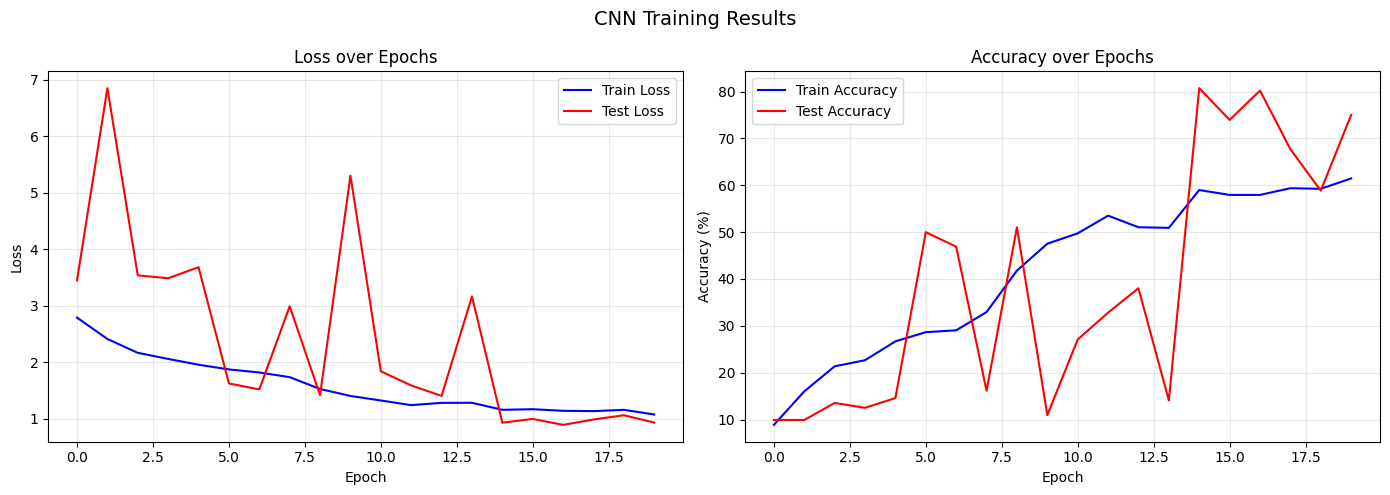


Final CNN Test Accuracy: 75.00%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label='Train Loss', color='blue')
axes[0].plot(test_losses,  label='Test Loss',  color='red')
axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(train_accs, label='Train Accuracy', color='blue')
axes[1].plot(test_accs,  label='Test Accuracy',  color='red')
axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('CNN Training Results', fontsize=14)
plt.tight_layout()
plt.savefig('cnn_training.png', dpi=150)
plt.show()

print(f"\nFinal CNN Test Accuracy: {test_accs[-1]:.2f}%")

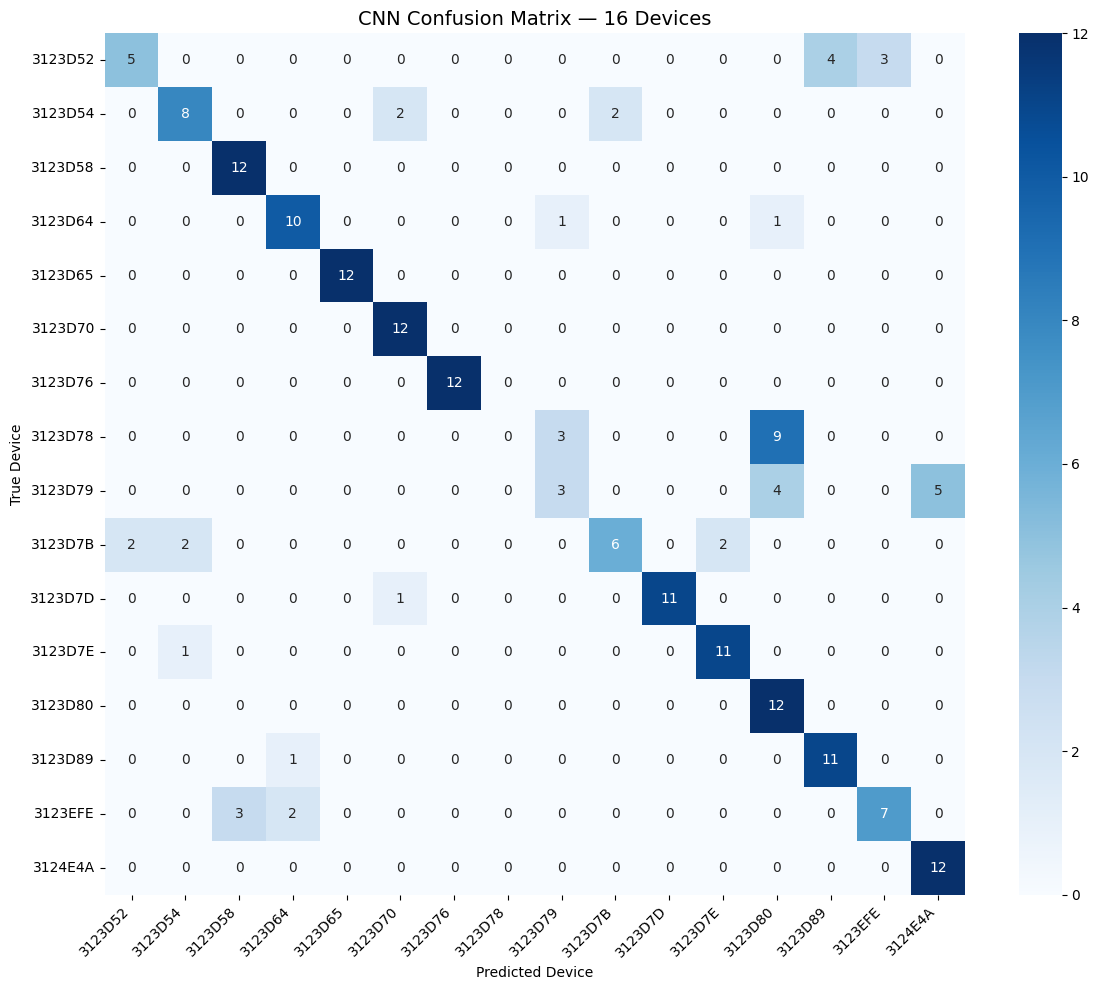


Classification Report:
              precision    recall  f1-score   support

     3123D52       0.71      0.42      0.53        12
     3123D54       0.73      0.67      0.70        12
     3123D58       0.80      1.00      0.89        12
     3123D64       0.77      0.83      0.80        12
     3123D65       1.00      1.00      1.00        12
     3123D70       0.80      1.00      0.89        12
     3123D76       1.00      1.00      1.00        12
     3123D78       0.00      0.00      0.00        12
     3123D79       0.43      0.25      0.32        12
     3123D7B       0.75      0.50      0.60        12
     3123D7D       1.00      0.92      0.96        12
     3123D7E       0.85      0.92      0.88        12
     3123D80       0.46      1.00      0.63        12
     3123D89       0.73      0.92      0.81        12
     3123EFE       0.70      0.58      0.64        12
     3124E4A       0.71      1.00      0.83        12

    accuracy                           0.75       192
  

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get all predictions
cnn_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs     = cnn_model(X_batch.to(device))
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(y_batch.numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=device_ids,
            yticklabels=device_ids)
plt.title('CNN Confusion Matrix — 16 Devices', fontsize=14)
plt.ylabel('True Device')
plt.xlabel('Predicted Device')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix_cnn.png', dpi=150)
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds,
                             target_names=device_ids))

# Save model
torch.save(cnn_model.state_dict(), 'cnn_model.pth')
print("\nCNN model saved!")

In [ ]:
class RFFingerprint_LSTM(nn.Module):
    def __init__(self, input_size=2, hidden_size=128,
                 num_layers=2, num_classes=16):
        super(RFFingerprint_LSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,    # I and Q = 2 features
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.3
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x shape: (batch, seq_len, 2)
        lstm_out, (hn, cn) = self.lstm(x)
        # Use last hidden state
        out = self.classifier(hn[-1])
        return out

lstm_model = RFFingerprint_LSTM(num_classes=num_classes).to(device)
print(lstm_model)
print(f"\nTotal parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")

RFFingerprint_LSTM(
  (lstm): LSTM(2, 128, num_layers=2, batch_first=True, dropout=0.3)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=16, bias=True)
  )
)

Total parameters: 208,976


In [ ]:
def load_lstm_dataset(dataset_path, distance='2ft',
                      seq_len=512, num_chunks_per_file=30):
    """Load raw IQ as (I, Q) sequences for LSTM."""

    dist_path = os.path.join(dataset_path, distance)

    device_ids_set = set()
    for f in os.listdir(dist_path):
        if f.endswith('.sigmf-data'):
            device_ids_set.add(f.split('_')[3])

    device_ids_lst = sorted(list(device_ids_set))
    dev_to_lbl     = {d: i for i, d in enumerate(device_ids_lst)}

    X, y = [], []

    for filename in sorted(os.listdir(dist_path)):
        if not filename.endswith('.sigmf-data'):
            continue

        device_id = filename.split('_')[3]
        label     = dev_to_lbl[device_id]
        filepath  = os.path.join(dist_path, filename)

        raw_iq = np.fromfile(filepath, dtype=np.complex128)

        for i in range(num_chunks_per_file):
            start = i * seq_len
            end   = start + seq_len
            if end > len(raw_iq):
                break

            chunk = raw_iq[start:end]
            # Stack I and Q as two features
            iq_2d = np.stack([chunk.real,
                              chunk.imag], axis=1).astype(np.float32)
            # shape: (seq_len, 2)
            X.append(iq_2d)
            y.append(label)

    return np.array(X), np.array(y), device_ids_lst

print("Loading LSTM dataset...")
X_lstm, y_lstm, _ = load_lstm_dataset(
    dataset_path, distance='2ft', num_chunks_per_file=30)

print(f"LSTM X shape: {X_lstm.shape}  (samples, seq_len, features)")
print(f"LSTM y shape: {y_lstm.shape}")

# Split
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = \
    train_test_split(X_lstm, y_lstm, test_size=0.2,
                     random_state=42, stratify=y_lstm)

train_loader_lstm = DataLoader(
    RFDataset(X_train_lstm, y_train_lstm),
    batch_size=32, shuffle=True)

test_loader_lstm  = DataLoader(
    RFDataset(X_test_lstm, y_test_lstm),
    batch_size=32, shuffle=False)

print("LSTM data ready!")

Loading LSTM dataset...
LSTM X shape: (960, 512, 2)  (samples, seq_len, features)
LSTM y shape: (960,)
LSTM data ready!


In [ ]:
print("Training LSTM model...")
print("="*70)

lstm_train_losses, lstm_test_losses, \
lstm_train_accs,   lstm_test_accs = train_model(
    lstm_model, train_loader_lstm, test_loader_lstm,
    num_epochs=20)

torch.save(lstm_model.state_dict(), 'lstm_model.pth')
print(f"\nFinal LSTM Test Accuracy: {lstm_test_accs[-1]:.2f}%")

Training LSTM model...
Epoch [ 1/20] Train Loss: 2.7773  Train Acc: 5.2%  Test Loss: 2.7743  Test Acc: 6.2%
Epoch [ 2/20] Train Loss: 2.7755  Train Acc: 6.4%  Test Loss: 2.7740  Test Acc: 6.2%
Epoch [ 3/20] Train Loss: 2.7756  Train Acc: 5.7%  Test Loss: 2.7738  Test Acc: 6.2%
Epoch [ 4/20] Train Loss: 2.7748  Train Acc: 6.4%  Test Loss: 2.7736  Test Acc: 6.2%
Epoch [ 5/20] Train Loss: 2.7741  Train Acc: 6.6%  Test Loss: 2.7736  Test Acc: 6.2%
Epoch [ 6/20] Train Loss: 2.7743  Train Acc: 6.6%  Test Loss: 2.7734  Test Acc: 6.2%
Epoch [ 7/20] Train Loss: 2.7733  Train Acc: 5.2%  Test Loss: 2.7733  Test Acc: 6.2%
Epoch [ 8/20] Train Loss: 2.7741  Train Acc: 5.7%  Test Loss: 2.7731  Test Acc: 6.2%
Epoch [ 9/20] Train Loss: 2.7739  Train Acc: 6.5%  Test Loss: 2.7732  Test Acc: 6.2%
Epoch [10/20] Train Loss: 2.7729  Train Acc: 6.9%  Test Loss: 2.7730  Test Acc: 6.2%
Epoch [11/20] Train Loss: 2.7734  Train Acc: 5.9%  Test Loss: 2.7730  Test Acc: 6.2%
Epoch [12/20] Train Loss: 2.7735  Train Ac

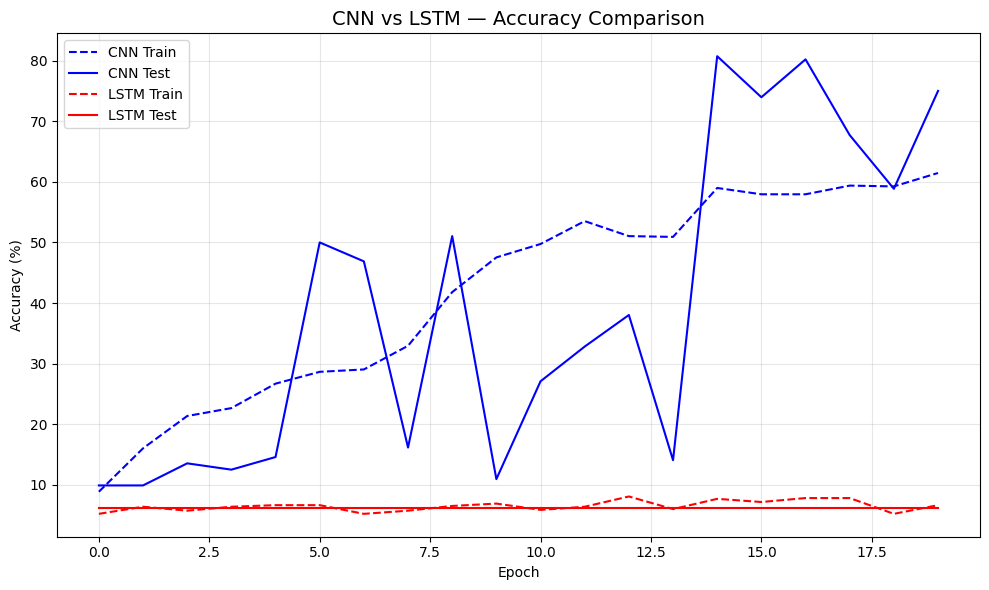

Final Accuracies at 2ft clean signal:
  CNN  Test Accuracy:  75.00%
  LSTM Test Accuracy:  6.25%


In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(train_accs,      label='CNN Train',  color='blue',   linestyle='--')
plt.plot(test_accs,       label='CNN Test',   color='blue',   linestyle='-')
plt.plot(lstm_train_accs, label='LSTM Train', color='red',    linestyle='--')
plt.plot(lstm_test_accs,  label='LSTM Test',  color='red',    linestyle='-')

plt.title('CNN vs LSTM — Accuracy Comparison', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('cnn_vs_lstm.png', dpi=150)
plt.show()

print(f"Final Accuracies at 2ft clean signal:")
print(f"  CNN  Test Accuracy:  {test_accs[-1]:.2f}%")
print(f"  LSTM Test Accuracy:  {lstm_test_accs[-1]:.2f}%")

Loading raw IQ for noise experiment...
SNR =   30dB  |  CNN: 14.6%  |  LSTM: 6.2%
SNR =   20dB  |  CNN: 13.5%  |  LSTM: 6.2%
SNR =   10dB  |  CNN: 16.7%  |  LSTM: 6.2%
SNR =    0dB  |  CNN: 12.0%  |  LSTM: 6.2%
SNR =  -10dB  |  CNN: 10.9%  |  LSTM: 6.2%


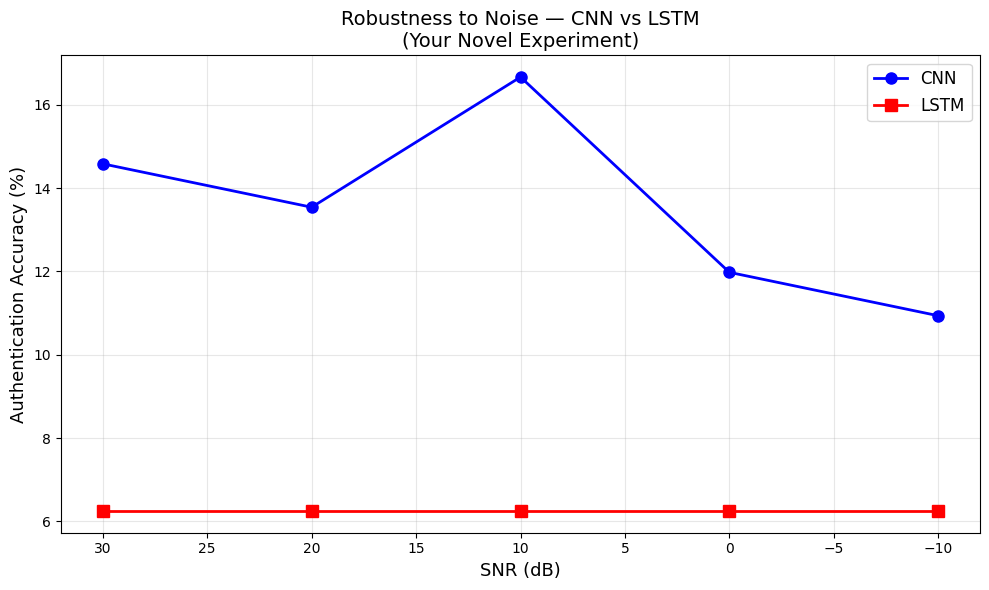

In [ ]:
def add_awgn_noise(iq_signal, snr_db):
    """Add Gaussian noise at given SNR level."""
    signal_power = np.mean(np.abs(iq_signal)**2)
    snr_linear   = 10 ** (snr_db / 10)
    noise_power  = signal_power / snr_linear
    noise        = (np.sqrt(noise_power/2) *
                   (np.random.randn(*iq_signal.shape) +
                    1j * np.random.randn(*iq_signal.shape)))
    return iq_signal + noise

def test_at_snr(model, X_test_raw_iq, y_test,
                snr_db, model_type='cnn'):
    """Test model at a specific SNR level."""
    model.eval()
    correct, total = 0, 0

    batch_size = 32
    for i in range(0, len(X_test_raw_iq), batch_size):
        X_batch_iq = X_test_raw_iq[i:i+batch_size]
        y_batch    = y_test[i:i+batch_size]

        # Add noise
        noisy_batch = np.array([
            add_awgn_noise(iq, snr_db) for iq in X_batch_iq
        ])

        if model_type == 'cnn':
            # Convert to spectrogram
            specs = []
            for iq in noisy_batch:
                _, _, Sxx = scipy_signal.spectrogram(
                    iq, fs=5e6, nperseg=128,
                    noverlap=64, nfft=256, return_onesided=False)
                Sxx_db = 10 * np.log10(np.abs(Sxx) + 1e-10)
                Sxx_norm = (Sxx_db - Sxx_db.min()) / \
                           (Sxx_db.max() - Sxx_db.min() + 1e-10)
                specs.append(Sxx_norm.astype(np.float32))
            X_in = torch.tensor(
                np.array(specs)[:, np.newaxis], dtype=torch.float32
            ).to(device)
        else:
            # LSTM: stack I and Q
            iq_2d = np.stack(
                [noisy_batch.real, noisy_batch.imag], axis=2
            ).astype(np.float32)
            X_in  = torch.tensor(iq_2d, dtype=torch.float32).to(device)

        with torch.no_grad():
            outputs     = model(X_in)
            _, predicted = torch.max(outputs, 1)

        y_t      = torch.tensor(y_batch, dtype=torch.long)
        correct += (predicted.cpu() == y_t).sum().item()
        total   += len(y_batch)

    return 100 * correct / total

# Load raw IQ test samples for noise experiment
print("Loading raw IQ for noise experiment...")

# Use the already-loaded X_lstm which has raw IQ structure
# We need to reload a sample of raw IQ
snr_levels   = [30, 20, 10, 0, -10]
cnn_snr_accs  = []
lstm_snr_accs = []

# Take subset for speed
X_test_iq_raw = X_test_lstm[:200]   # raw IQ sequences
y_test_subset = y_test_lstm[:200]

for snr in snr_levels:
    # Convert sequences back to complex
    X_complex = X_test_iq_raw[:, :, 0] + 1j * X_test_iq_raw[:, :, 1]

    cnn_acc  = test_at_snr(cnn_model,  X_complex, y_test_subset, snr, 'cnn')
    lstm_acc = test_at_snr(lstm_model, X_complex, y_test_subset, snr, 'lstm')

    cnn_snr_accs.append(cnn_acc)
    lstm_snr_accs.append(lstm_acc)

    print(f"SNR = {snr:4d}dB  |  CNN: {cnn_acc:.1f}%  |  LSTM: {lstm_acc:.1f}%")

# Plot SNR robustness
plt.figure(figsize=(10, 6))
plt.plot(snr_levels, cnn_snr_accs,  'bo-', label='CNN',  linewidth=2, markersize=8)
plt.plot(snr_levels, lstm_snr_accs, 'rs-', label='LSTM', linewidth=2, markersize=8)
plt.xlabel('SNR (dB)', fontsize=13)
plt.ylabel('Authentication Accuracy (%)', fontsize=13)
plt.title('Robustness to Noise — CNN vs LSTM\n(Your Novel Experiment)', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.savefig('snr_robustness.png', dpi=150)
plt.show()